# TOT_Skewness: 電子飛跡の再構成

TPC のエンコーダのヒット(ストリップ × クロック)から、反跳電子の**散乱点 `Pe`**、**進行方向 `Ve`**、**飛程 `Len`** を求めます。
SMILE_tool_box の `TOT_Skewness_Analysis` に相当します。

1. **TOT 補正**: 各ストリップの立ち上がりクロックを TOT(信号幅)で補正する
2. **3 次元同時計数**: 補正後のクロックでアノード(x)とカソード(y)を対応させ、3 次元の点群を作る
3. **座標変換**: x, y はストリップ × 0.8 mm、z は `(クロック − オフセット) × ドリフト速度`
4. **飛程**: 点群を囲む箱の対角線の長さ(`Track_Min`, `Track_Max` はその角)
5. **skewness**: 電荷分布の歪みから、飛跡の始点(散乱点)側を判定して `Pe` を決める
6. **方向**: 散乱点付近の TOT 補正後の点を、x-z 面と y-z 面でそれぞれ直線 $z = a\,(x - P_{e,x}) + P_{e,z}$ でフィットし、
   電子の進行方向 `Ve` を求める

### 出力の中身(添字 0 = x, 1 = y, 2 = z、単位 mm)

| 量 | 中身 |
|---|---|
| `Pe[0..2]` | 散乱点の x, y, z |
| `Ve[0..2]` | 電子の進行方向の x, y, z 成分。$s\,(1/a_x,\ 1/a_y,\ 1)$ = $s\,(dx/dz,\ dy/dz,\ 1)$ で、**長さ 1 ではない**。$s = \pm 1$ は散乱点より上(z が大きい側)と下のどちらにヒットが多いかで決める。フィットに失敗した軸があると、xy 面内の単位ベクトルと `Ve[2] = 0` になる |
| `Len` | 飛程。`Track_Min[0..2]` と `Track_Max[0..2]`(飛跡を囲む箱の角の x, y, z)の対角線の長さ |

再構成ツリー `single_hit` では `Pe_TRA[0..2]`、`Ve_TRA[0..2]`、`Len_TRA` に入ります(`[3..5]` は使わない枠)。

### ドリフト速度

ガスの状態でドリフト速度が時間変化するので、`drift_velocity.dat`(1 行目がクロックのオフセット、
以降が「経過時間 [h]、速度 [mm/clock]」の表)を、**イベントごとの時刻**(TPC 生データのヘッダにある
DAQ 開始からの経過時間カウンタ、生データツリーの `anode_time`)で引きます。

### パラメータ

| パラメータ | 値 | 意味 |
|---|---|---|
| `drift_velocity_file` | `Per02_ETCC/drift_velocity.dat` | ドリフト速度の表 |
| `pitch_x_mm_per_strip`, `pitch_y_mm_per_strip` | 0.8 | ストリップピッチ [mm] |
| `flag_pixel_cut` | `False` | 不良ピクセルを除くか |
| `flag_save_cloud` | `False` | 点群をツリーに保存するか |

In [1]:
import sys, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ROOT
ROOT.gROOT.SetBatch(True)

# リポジトリの場所、チェーンの実行スクリプト、設定ファイル(config/*.json)の読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CACHE = REPO / "tutorials" / "cache"   # チェーンの出力の置き場(チュートリアル間で共有)
CACHE.mkdir(exist_ok=True)

def vec(column):
    """RDataFrame.AsNumpy() の配列型の列 -> 2 次元の numpy 配列"""
    return np.stack([np.asarray(v) for v in column])

## 1. データのダウンロード

このチュートリアルでは 20190701 の較正データ **Per02**(線源を TPC の上方 z = −1626 mm に置いた測定)を使います。
生データ(約 17 GB)とパラメータはリポジトリに含まれていないので、研究室サーバーから手元にコピーします。

```bash
mkdir -p ~/smile2p_data
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/Per02_ETCC ~/smile2p_data/
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param ~/smile2p_data/
```

(`<user>` は自分のアカウント名)

- 途中で切れても同じコマンドで続きからコピーされます。
- `~/smile2p_data` 以外に置いた場合は、環境変数 `SMILE2P_DATA` にその場所を設定してください
  (Jupyter を起動する前に `export SMILE2P_DATA=/path/to/data`)。
- 上の形(`<置き場>/Per02_ETCC`、`<置き場>/param/20190528`)で置けば設定ファイルは書き換え不要です。
  置き方が違う場合は、設定ファイル `config/smile2p_20190701_Per02.json` の
  `ReadData.data_dir`、`TPC_Calibration.ParameterFile`、`HA_Calc.parameter_dir`、
  `HA_Calc.Modified_Parameter_Data_Dir`、`TOT_Skewness.drift_velocity_file` を自分のパスに書き換えます
  (詳しくはリポジトリ直下の README の「自分の環境に合わせて変える場所」)。
- サーバー上で実行する場合はコピーしなくても動きます(サーバー上の場所をそのまま使います)。
  ただし実行時間の大半は生データの読み込みなので、**手元のディスクにコピーした方が大幅に速く**なります
  (ネットワーク越しの場所から読むと約 10 倍遅い)。

設定ファイル `config/smile2p_20190701_Per02.json` に、データの場所(`{data_top}` はデータの置き場に置き換わる)と
各モジュールのパラメータが書かれています。データが見つかるか確認します(`MISSING` なら上のコマンドでコピー)。

In [2]:
CONFIG = "smile2p_20190701_Per02"
cfg = ec.load(CONFIG)
print("data_top:", ec.data_top())
for path in [cfg["parameters"]["ReadData"]["data_dir"], cfg["parameters"]["HA_Calc"]["parameter_dir"]]:
    print("OK     " if Path(path).is_dir() else "MISSING", path)

data_top: /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata
OK      /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/Per02_ETCC
OK      /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param/20190528


## 2. ドリフト速度の表

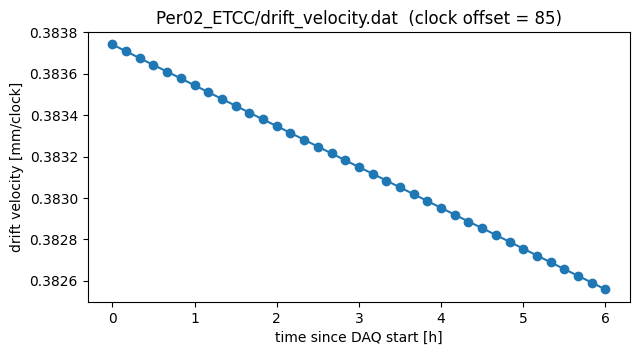

In [3]:
table = Path(cfg["parameters"]["TOT_Skewness"]["drift_velocity_file"])   # 設定ファイルに書かれた表
lines = table.read_text().split()
offset, vals = float(lines[0]), np.array(lines[1:], float).reshape(-1, 2)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(vals[:, 0], vals[:, 1], "o-")
ax.set_xlabel("time since DAQ start [h]"); ax.set_ylabel("drift velocity [mm/clock]")
ax.set_title(f"{table.parent.name}/{table.name}  (clock offset = {offset:g})")
plt.show()

## 3. 再構成ツリーを読む

全チェーンを先頭 50000 イベントで実行し(DataIO と同じ出力を共有。既にあれば再実行しない)、
再構成ツリー `Reconstruct/single_hit` の `err_flag == 0` の行を読みます。

In [4]:
OUT = CACHE / "Per02_50000.root"
cmd = [sys.executable, str(RUN_CHAIN), CONFIG, "-o", str(OUT), "-n", "50000"]
print(" ".join(cmd))
if not OUT.exists():
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
    r.check_returncode()

/usr/bin/python3 /home/onoda/ANLNext/EricaNext_try/run_script/run_chain.py smile2p_20190701_Per02 -o /home/onoda/ANLNext/EricaNext_try/tutorials/cache/Per02_50000.root -n 50000


In [5]:
d = ROOT.RDataFrame("Reconstruct/single_hit", str(OUT)).Filter("err_flag == 0").AsNumpy(['err_flag', 'Len_TRA', 'skewness_x', 'skewness_y', 'Track_Min', 'Track_Max', 'Pe_TRA'])
ev = {k: (vec(v) if v.dtype == object else v) for k, v in d.items()}   # 配列型の列は 2 次元配列に
print("err_flag == 0:", len(ev["err_flag"]))

err_flag == 0: 26697


## 4. 飛跡の分布

飛程、skewness、飛跡の端点(`Track_Min`, `Track_Max`)の x-z, y-z 分布です。

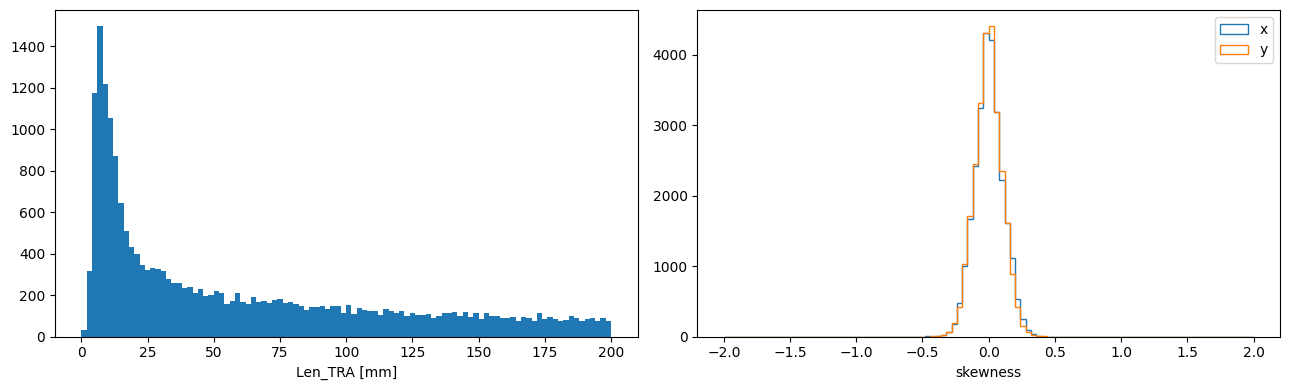

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(ev["Len_TRA"], bins=100, range=(0, 200)); ax[0].set_xlabel("Len_TRA [mm]")
ax[1].hist(ev["skewness_x"], bins=100, range=(-2, 2), histtype="step", label="x")
ax[1].hist(ev["skewness_y"], bins=100, range=(-2, 2), histtype="step", label="y")
ax[1].set_xlabel("skewness"); ax[1].legend()
fig.tight_layout(); plt.show()

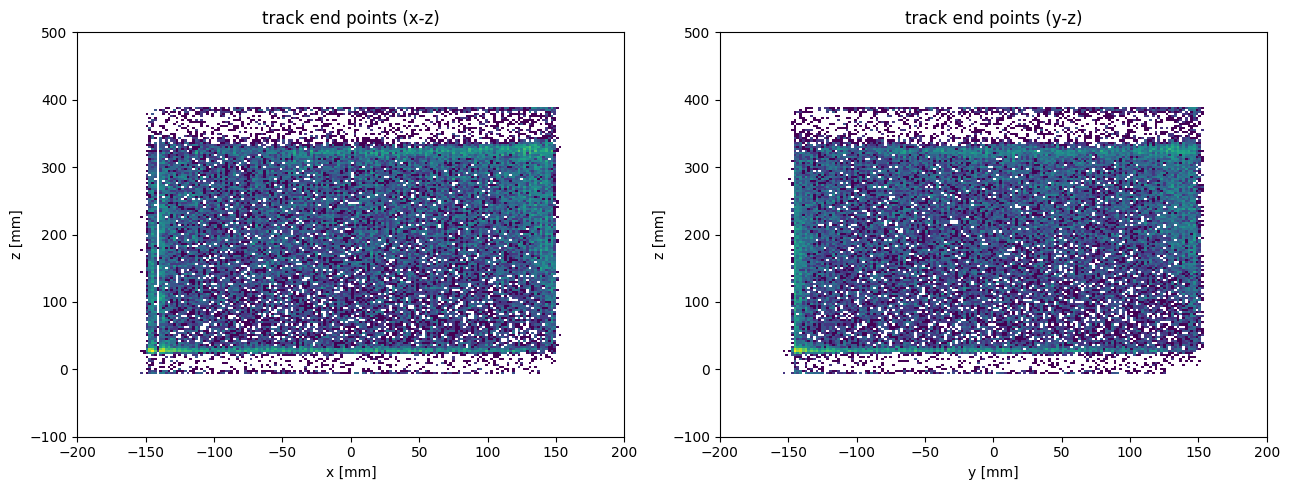

In [7]:
ends = np.concatenate([ev["Track_Min"], ev["Track_Max"]])
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, k, lab in [(ax[0], 0, "x"), (ax[1], 1, "y")]:
    a.hist2d(ends[:, k], ends[:, 2], bins=[200, 200], range=[[-200, 200], [-100, 500]], cmin=1, norm="log")
    a.set_xlabel(f"{lab} [mm]"); a.set_ylabel("z [mm]"); a.set_title(f"track end points ({lab}-z)")
fig.tight_layout(); plt.show()